# CS336 lecture 2 helper

This reference companion records the tutoring lesson from October 17 to 19, 2026.
It was written by the teaching assistant from that lesson. It is not an original
implementation submitted by the learner, and it is not a CS336 assignment solution.

References:
- [Stanford CS336](https://cs336.stanford.edu/)
- [Lecture 2 recording](https://www.youtube.com/watch?v=kuYAsz7zspQ)
- [Official lecture code](https://github.com/stanford-cs336/lectures/blob/main/lecture_02.py)
- [Supplementary AI-generated notes](https://qihongruan.github.io/cs336/lec02.html), which omit some lecture material.

Run the cells from top to bottom on CPU. Python, NumPy, PyTorch, and Matplotlib
are required. No training data, GPU, or external download is needed by these cells.
The saved outputs are numerical reference checks, not GPU benchmarks.

One way to start a suitable environment is:

```bash
uv run --python 3.12 --with numpy --with torch --with matplotlib --with jupyterlab jupyter lab
```

The formula for AdaGrad below follows the lecture, with the small constant
inside the square root. Do not assume that every library uses that placement.


## The map

1. Count a scalar forward pass.
2. Count a matrix forward pass.
3. Derive scalar and batch gradients.
4. Explain intermediate gradients and verify both matrix backward products.
5. Update weights with gradient descent.
6. Update weights and stored state with AdaGrad.
7. Count memory traffic and arithmetic intensity.

Our layer and scalar batch loss are:

$$
\widehat{Y}=XW,
\qquad
L=\frac{1}{2B}\sum_b\sum_k(\hat{y}_{bk}-t_{bk})^2.
$$

We sum across outputs and average across examples. This differs from averaging
all squared-error entries, which would divide by the output count as well.

The complete gradient formulas are:

$$
E=\widehat{Y}-T,
\qquad G=E/B,
\qquad \nabla_W L=X^{\mathsf T}G,
\qquad \nabla_X L=GW^{\mathsf T}.
$$

Use display mathematics throughout. Inline LaTeX did not render reliably in the chat.


In [1]:
import math
import sys
import numpy as np
import torch
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('PyTorch:', torch.__version__)
print('Device: CPU; float64 for derivative checks; FP32 only in byte-count formulas.')


Python: 3.12.11
NumPy: 2.5.4
PyTorch: 2.14.1
Device: CPU; float64 for derivative checks; FP32 only in byte-count formulas.


## Step 1: Scalar forward operations

A dot product of length five needs five multiplications and four additions.
After the prediction exists, half the squared error needs one subtraction and
two multiplications. Increasing the feature count from three to five adds four
operations to the prediction, but no work to the unchanged loss formula.

**Stop here.** Calculate the prediction and full-forward costs for both lengths.
The code below is a reference check.

Python primitives: integer multiplication, addition, and subtraction. These
calculations do not allocate tensors and do not measure execution time.


In [2]:
def dot_flops(length):
    """Count multiplications plus the additions needed to sum the products."""
    if length < 1:
        raise ValueError('A dot product must have at least one term.')
    return length + (length - 1)

for length in (3, 5):
    prediction_cost = dot_flops(length)
    print({'features': length, 'prediction': prediction_cost,
           'loss_after_prediction': 3, 'total': prediction_cost + 3})
assert dot_flops(3) + 3 == 8
assert dot_flops(5) + 3 == 12


{'features': 3, 'prediction': 5, 'loss_after_prediction': 3, 'total': 8}
{'features': 5, 'prediction': 9, 'loss_after_prediction': 3, 'total': 12}


## Step 2: Matrix forward operations

$$
X\in\mathbb R^{B\times D},\qquad
W\in\mathbb R^{D\times K},\qquad
\widehat Y\in\mathbb R^{B\times K}.
$$

Each output is a dot product across input features. The exact product count and
the conventional leading estimate are:

$$
BK(2D-1),\qquad 2BDK.
$$

**Stop here.** Use a batch size of four, three input features, and two outputs.
Find the output shape, parameter count, and both counts.

Primitives: `torch.ones(rows, columns)` creates a matrix; `@` multiplies matrices;
`.shape` reports dimensions; `.numel()` counts entries.


In [3]:
B, D, K = 4, 3, 2
x_demo = torch.ones(B, D)
w_demo = torch.ones(D, K)
print('Prediction shape:', tuple((x_demo @ w_demo).shape))
print('Parameters:', w_demo.numel())
print('Exact forward product:', B * K * dot_flops(D))
print('Approximate forward product:', 2 * B * D * K)
assert tuple((x_demo @ w_demo).shape) == (4, 2)
assert B * K * dot_flops(D) == 40


Prediction shape: (4, 2)
Parameters: 6
Exact forward product: 40
Approximate forward product: 48


## Step 3: Derive before calling backward

For one example:

$$
L=\frac12(\mathbf x\cdot\mathbf w-t)^2,
\qquad
\frac{\partial L}{\partial w_i}=(\hat y-t)x_i.
$$

For a batch with one output per example:

$$
\frac{\partial L}{\partial w_i}
=\frac1B\sum_b(\hat y_b-t_b)x_{bi}.
$$

**Stop here.** With input values one, two, and three and weights all equal to
one, derive the gradient for a target of eight. Explain which input each
example uses before moving to the two-example check.

Primitives: `requires_grad=True` tracks a parameter; `.backward()` calculates
gradients; `.grad` holds the resulting parameter gradient. Fresh tensors below
prevent gradients from an earlier example accumulating into a later check.


In [4]:
x = torch.tensor([1., 2., 3.], dtype=torch.float64)
w = torch.ones(3, dtype=torch.float64, requires_grad=True)
prediction = x @ w
loss = 0.5 * (prediction - 8).square()
loss.backward()
print('Prediction:', prediction.item(), 'Error:', prediction.item() - 8)
print('Gradient:', w.grad.tolist())
torch.testing.assert_close(w.grad, torch.tensor([-2., -4., -6.], dtype=w.dtype))

x_batch = torch.tensor([[1., 2., 3.], [4., 5., 6.]], dtype=torch.float64)
targets = torch.tensor([8., 14.], dtype=torch.float64)
for reduction in ('mean', 'sum'):
    weights = torch.ones(3, dtype=torch.float64, requires_grad=True)
    per_example_loss = 0.5 * (x_batch @ weights - targets).square()
    batch_loss = getattr(per_example_loss, reduction)()
    batch_loss.backward()
    expected = [1., 0.5, 0.] if reduction == 'mean' else [2., 1., 0.]
    torch.testing.assert_close(weights.grad, torch.tensor(expected, dtype=weights.dtype))
    print(reduction, 'loss:', batch_loss.item(), 'gradient:', weights.grad.tolist())


Prediction: 6.0 Error: -2.0
Gradient: [-2.0, -4.0, -6.0]


mean loss: 1.25 gradient: [1.0, 0.5, 0.0]


sum loss: 2.5 gradient: [2.0, 1.0, 0.0]


## Step 4: Why an intermediate value needs a gradient

Start with the earlier parameter whose gradient we need:

$$
x=f(a,b)=ab,\qquad \hat y=g(x,w)=xw,\qquad
L=\frac12(\hat y-y)^2.
$$

$$
\frac{\partial L}{\partial b}
=\underbrace{\frac{\partial L}{\partial\hat y}
\frac{\partial\hat y}{\partial x}}_{\partial L/\partial x}
\frac{\partial x}{\partial b}.
$$

The intermediate gradient is the link to the earlier parameter. The optimizer
does not directly update the intermediate value. The next forward pass
recomputes it from the updated parameters.

**Stop here.** Use input two, earlier weight three, later weight four, and
target twenty. Derive the intermediate gradient and the earlier weight gradient.

Primitives: `.retain_grad()` retains the gradient of an intermediate tensor for
inspection. Without it, autograd still propagates that gradient, but does not
normally keep the intermediate tensor's `.grad` field.


Intermediate: 6.0 Prediction: 24.0 Loss: 8.0
Intermediate gradient: 16.0
Earlier weight gradient: 32.0


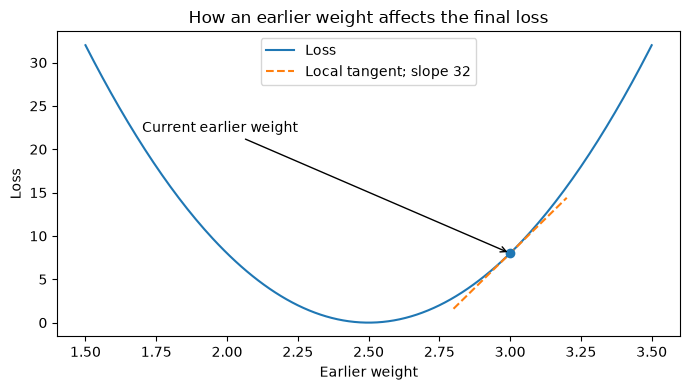

In [5]:
a = torch.tensor(2., dtype=torch.float64)
b = torch.tensor(3., dtype=torch.float64, requires_grad=True)
later_weight = torch.tensor(4., dtype=torch.float64, requires_grad=True)
intermediate = a * b
intermediate.retain_grad()
prediction = intermediate * later_weight
loss = 0.5 * (prediction - 20).square()
loss.backward()
print('Intermediate:', intermediate.item(), 'Prediction:', prediction.item(), 'Loss:', loss.item())
print('Intermediate gradient:', intermediate.grad.item())
print('Earlier weight gradient:', b.grad.item())
assert intermediate.grad.item() == 16.
assert b.grad.item() == 32.

# Visualize the actual scalar loss and its local tangent at the old weight.
b_values = np.linspace(1.5, 3.5, 201)
loss_values = 0.5 * (2 * b_values * 4 - 20) ** 2
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(b_values, loss_values, label='Loss')
local = np.linspace(2.8, 3.2, 41)
ax.plot(local, 8 + 32 * (local - 3), '--', label='Local tangent; slope 32')
ax.scatter([3], [8], zorder=3)
ax.annotate('Current earlier weight', (3, 8), xytext=(1.7, 22),
            arrowprops={'arrowstyle': '->'})
ax.set(xlabel='Earlier weight', ylabel='Loss', title='How an earlier weight affects the final loss')
ax.legend()
fig.tight_layout()
plt.show()


## Step 4 continued: Two matrix backward products

For our specified scalar batch loss:

$$
\frac{\partial L}{\partial w_{ik}}=\sum_b x_{bi}G_{bk},
\qquad
\frac{\partial L}{\partial x_{bi}}=\sum_k G_{bk}w_{ik},
\qquad G=E/B.
$$

Weights combine paths across examples. Inputs combine paths across outputs.
The full-loss output sensitivity already includes the mean-loss factor.

**Stop here.** Derive both formulas for one entry, then derive the shapes of
the matrix products. Count the dot products before averaging. The reference
below compares both manual derivatives with autograd and checks one weight
by finite differences.

Primitives: `.sum(dim=1)` sums outputs within each example; `.mean()` averages
example losses; `.transpose(0, 1)` exchanges the two axes; `.detach()` reads a
value without extending the graph; `torch.testing.assert_close` compares numbers.


In [6]:
generator = torch.Generator().manual_seed(336)
B, D, K = 4, 3, 2
x = torch.randn(B, D, generator=generator, dtype=torch.float64, requires_grad=True)
w = torch.randn(D, K, generator=generator, dtype=torch.float64, requires_grad=True)
target = torch.randn(B, K, generator=generator, dtype=torch.float64)
prediction = x @ w
error = prediction - target
loss = (0.5 * error.square().sum(dim=1)).mean()
loss.backward()

output_gradient = error.detach() / B
manual_weight_gradient = x.detach().transpose(0, 1) @ output_gradient
manual_input_gradient = output_gradient @ w.detach().transpose(0, 1)
torch.testing.assert_close(w.grad, manual_weight_gradient)
torch.testing.assert_close(x.grad, manual_input_gradient)

def scalar_loss_for_weights(weights):
    return (0.5 * (x.detach() @ weights - target).square().sum(dim=1)).mean()

h = 1e-6
plus, minus = w.detach().clone(), w.detach().clone()
plus[0, 1] += h
minus[0, 1] -= h
finite_difference = (scalar_loss_for_weights(plus) - scalar_loss_for_weights(minus)) / (2 * h)
torch.testing.assert_close(finite_difference, w.grad[0, 1], rtol=1e-6, atol=1e-7)
print('Manual weight and input derivatives match autograd.')
print('One weight: analytic =', w.grad[0, 1].item(), 'finite difference =', finite_difference.item())

exact = {'forward': B * K * dot_flops(D),
         'weight product': D * K * dot_flops(B),
         'input product': B * D * dot_flops(K)}
print('Exact matrix-product FLOPs:', exact)
print('Approximate FLOPs per product:', 2 * B * D * K)
print('Final weight gradients:', D * K, 'Per-example contributions:', B * D * K)
assert exact == {'forward': 40, 'weight product': 42, 'input product': 36}


Manual weight and input derivatives match autograd.
One weight: analytic = 0.3468827516723148 finite difference = 0.3468827514119255
Exact matrix-product FLOPs: {'forward': 40, 'weight product': 42, 'input product': 36}
Approximate FLOPs per product: 48
Final weight gradients: 6 Per-example contributions: 24


## Step 5: Gradient descent

The gradient is a local sensitivity. A sufficiently small step in the negative
gradient direction reduces the loss locally:

$$
w_i^{\mathrm{new}}=w_i-\eta g_i.
$$

All entries use gradients from the same old parameter values. This update
requires one multiplication and one subtraction per parameter.

**Stop here.** With input values one, two, and three, unit weights, target five,
and learning rate 0.05, derive the updated weights, prediction, and loss.

Primitives: `torch.optim.SGD` without momentum or weight decay implements this
update; `.zero_grad(set_to_none=True)` clears old gradients; `.step()` updates
the weights. `torch.no_grad()` prevents recording evaluation or manual updates.


In [7]:
x = torch.tensor([1., 2., 3.], dtype=torch.float64)
w = torch.ones(3, dtype=torch.float64, requires_grad=True)
optimizer = torch.optim.SGD([w], lr=0.05)
optimizer.zero_grad(set_to_none=True)
loss = 0.5 * (x @ w - 5).square()
loss.backward()
optimizer.step()
with torch.no_grad():
    updated_prediction = x @ w
    updated_loss = 0.5 * (updated_prediction - 5).square()
torch.testing.assert_close(w, torch.tensor([0.95, 0.9, 0.85], dtype=w.dtype))
assert math.isclose(updated_loss.item(), 0.045, abs_tol=1e-12)
print('Weights:', w.detach().tolist())
print('Prediction:', updated_prediction.item(), 'Loss:', updated_loss.item())


Weights: [0.95, 0.9, 0.85]
Prediction: 5.3 Loss: 0.04499999999999995


## Step 6: AdaGrad and persistent state

Use the lecture's accumulator and denominator:

$$
s_i^{\mathrm{new}}=s_i+g_i^2,
\qquad
w_i^{\mathrm{new}}=w_i-\frac{\eta g_i}{\sqrt{s_i^{\mathrm{new}}+\varepsilon}}.
$$

The accumulator persists across updates. Larger accumulated squared gradients
reduce the effective learning rate. Count two multiplications, two additions,
one square root, one division, and one subtraction per parameter. Seven scalar
operations is a counting convention, not a promise of seven equal-cost GPU instructions.

**Stop here.** Start with weight one and zero state. Apply a gradient of two
with learning rate 0.1. Then apply a new gradient of one. For this example only,
omit the small constant because the updated denominators are nonzero.

Primitives: `torch.zeros_like` creates state with the weight's shape;
`.square()` and `.sqrt()` operate elementwise; `.add_()` and `.sub_()` update
existing tensors. The state is initialized once, not once per training step.


In [8]:
@torch.no_grad()
def lecture_adagrad_step_(weight, gradient, state, learning_rate, epsilon=1e-5):
    """Update weight and state in place, using epsilon inside the square root."""
    state.add_(gradient.square())
    weight.sub_(learning_rate * gradient / (state + epsilon).sqrt())

weight = torch.tensor([1.], dtype=torch.float64)
state = torch.zeros_like(weight)
lecture_adagrad_step_(weight, torch.tensor([2.], dtype=weight.dtype), state, 0.1, epsilon=0)
print('After first update:', {'weight': weight.item(), 'state': state.item()})
assert math.isclose(weight.item(), 0.9)
assert state.item() == 4.
lecture_adagrad_step_(weight, torch.tensor([1.], dtype=weight.dtype), state, 0.1, epsilon=0)
expected_weight = 0.9 - 0.1 / math.sqrt(5)
assert state.item() == 5.
assert math.isclose(weight.item(), expected_weight)
print('After second update:', {'weight': weight.item(), 'state': state.item()})


After first update: {'weight': 0.9, 'state': 4.0}
After second update: {'weight': 0.8552786404500042, 'state': 5.0}


## Step 7: Arithmetic intensity

For an ideal fused AdaGrad update, read the weight, gradient, and state. Write
the new weight and state. Temporaries remain on chip, and we ignore transfers
for the shared learning rate and stabilizer. Five FP32 values mean twenty bytes.

$$
I_{\mathrm{AdaGrad}}=\frac{7P}{20P}=0.35
\text{ counted scalar operations per byte}.
$$

For each matrix product, assume one read of each operand and one write of the
result, all FP32. Ignore reuse between separate products:

$$
I_{\mathrm{matrix}}\approx\frac{2BDK}{4(BD+DK+BK)}.
$$

**Stop here.** Use a batch size of 128 and both feature dimensions equal to
1024. Calculate operations, bytes, and their ratio.

These are analytical traffic estimates. Actual tiling, caches, extra kernels,
mixed precision, and existing-gradient accumulation can change traffic. An
intensity alone does not classify a kernel without the matching hardware
compute-to-bandwidth ratio. A tensor-core peak does not describe optimizer
square roots and divisions.


Approximate matrix-product FLOPs: 268,435,456
Ideal FP32 traffic in bytes: 5,242,880
Intensity in FLOPs per byte: 51.2
AdaGrad counted scalar operations per byte: 0.35


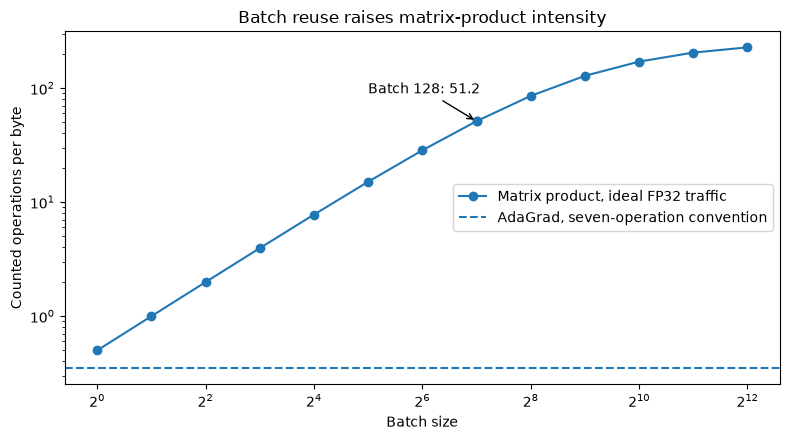

In [9]:
def matrix_accounting(batch, inputs, outputs, bytes_per_value=4):
    """Ideal standalone matrix product, using the leading FLOP convention."""
    operations = 2 * batch * inputs * outputs
    traffic = bytes_per_value * (batch * inputs + inputs * outputs + batch * outputs)
    return operations, traffic, operations / traffic

operations, traffic, intensity = matrix_accounting(128, 1024, 1024)
print('Approximate matrix-product FLOPs:', f'{operations:,}')
print('Ideal FP32 traffic in bytes:', f'{traffic:,}')
print('Intensity in FLOPs per byte:', intensity)
assert (operations, traffic) == (268435456, 5242880)
assert math.isclose(intensity, 51.2)

parameter_count = 1024 * 1024
optimizer_operations = 7 * parameter_count
optimizer_traffic = 5 * 4 * parameter_count
print('AdaGrad counted scalar operations per byte:', optimizer_operations / optimizer_traffic)
assert math.isclose(optimizer_operations / optimizer_traffic, 0.35)

batches = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096])
intensities = [matrix_accounting(int(batch), 1024, 1024)[2] for batch in batches]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(batches, intensities, marker='o', label='Matrix product, ideal FP32 traffic')
ax.axhline(0.35, linestyle='--', label='AdaGrad, seven-operation convention')
ax.scatter([128], [51.2], zorder=3)
ax.annotate('Batch 128: 51.2', (128, 51.2), xytext=(32, 90),
            arrowprops={'arrowstyle': '->'})
ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set(xlabel='Batch size', ylabel='Counted operations per byte',
       title='Batch reuse raises matrix-product intensity')
ax.legend()
fig.tight_layout()
plt.show()


## What carries forward

- State the loss reduction before deriving gradients.
- Start from the desired parameter gradient and follow its paths.
- An intermediate gradient connects the loss to earlier parameters.
- Per-example contributions and final parameter gradients are different counts.
- Two backward matrix products give the leading backward cost for an interior layer.
- The leading forward-plus-backward estimate excludes optimizer and other kernels:

$$
F\approx6BP,\qquad P=DK.
$$

- The first layer can skip raw-input gradients when those inputs are fixed.
- AdaGrad state persists. Clearing parameter gradients does not clear that state.
- Count values and bytes separately. State operand precisions and traffic assumptions.
- These numerical checks verify derivatives and calculations. They do not measure GPU performance.
